In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", context="notebook", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

tips = sns.load_dataset('tips')
print("Shape:", tips.shape)
tips.head()

Shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
print("=== INFO ===")
tips.info()
print("\n=== MISSING VALUES ===")
print(tips.isnull().sum())
print("\n=== DUPLICATES ===")
print("Duplicate rows:", tips.duplicated().sum())
print("\n=== NUMERIC SUMMARY ===")
display(tips.describe())
print("\n=== CATEGORICAL SUMMARY ===")
display(tips.describe(include='category'))

=== INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

=== MISSING VALUES ===
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

=== DUPLICATES ===
Duplicate rows: 1

=== NUMERIC SUMMARY ===


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00



=== CATEGORICAL SUMMARY ===


,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


In [3]:
for col in ['sex', 'smoker', 'day', 'time']:
    print(f"\n--- {col.upper()} ---")
    print(tips[col].value_counts(dropna=False))



--- SEX ---
sex
Male      157
Female     87
Name: count, dtype: int64

--- SMOKER ---
smoker
No     151
Yes     93
Name: count, dtype: int64

--- DAY ---
day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

--- TIME ---
time
Dinner    176
Lunch      68
Name: count, dtype: int64


In [4]:
tips['tip_pct'] = tips['tip'] / tips['total_bill'] * 100
tips['bill_per_person'] = tips['total_bill'] / tips['size']
tips['tip_per_person'] = tips['tip'] / tips['size']
tips['high_tipper'] = (tips['tip_pct'] >= tips['tip_pct'].quantile(0.75)).astype(int)
tips.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct,bill_per_person,tip_per_person,high_tipper
0,16.99,1.01,Female,No,Sun,Dinner,2,5.94,8.49,0.51,0
1,10.34,1.66,Male,No,Sun,Dinner,3,16.05,3.45,0.55,0
2,21.01,3.50,Male,No,Sun,Dinner,3,16.66,7.00,1.17,0
3,23.68,3.31,Male,No,Sun,Dinner,2,13.98,11.84,1.66,0
4,24.59,3.61,Female,No,Sun,Dinner,4,14.68,6.15,0.90,0


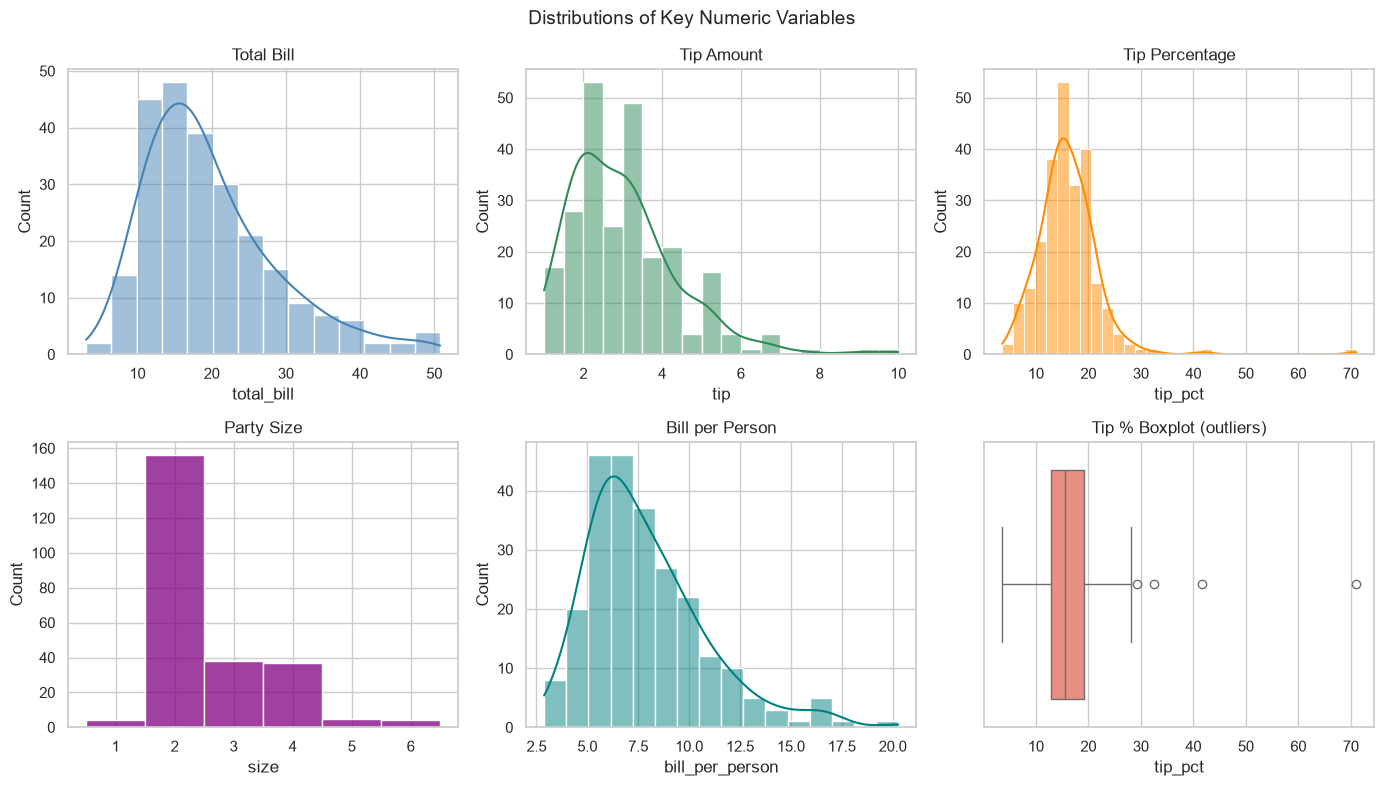

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle('Distributions of Key Numeric Variables', fontsize=14)

sns.histplot(tips['total_bill'], kde=True, ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Total Bill')

sns.histplot(tips['tip'], kde=True, ax=axes[0,1], color='seagreen')
axes[0,1].set_title('Tip Amount')

sns.histplot(tips['tip_pct'], kde=True, ax=axes[0,2], color='darkorange')
axes[0,2].set_title('Tip Percentage')

sns.histplot(tips['size'], discrete=True, ax=axes[1,0], color='purple')
axes[1,0].set_title('Party Size')

sns.histplot(tips['bill_per_person'], kde=True, ax=axes[1,1], color='teal')
axes[1,1].set_title('Bill per Person')

sns.boxplot(x=tips['tip_pct'], ax=axes[1,2], color='salmon')
axes[1,2].set_title('Tip % Boxplot (outliers)')

plt.tight_layout()
plt.show()


In [6]:
# Skewness check
print("Skewness:")
print(tips[['total_bill', 'tip', 'tip_pct', 'size']].skew().round(2))


Skewness:
total_bill   1.13
tip          1.47
tip_pct      3.35
size         1.45
dtype: float64


In [7]:
def find_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return series[(series < lower) | (series > upper)]

print("Outliers in total_bill:")
print(find_outliers_iqr(tips['total_bill']).sort_values())
print("\nOutliers in tip:")
print(find_outliers_iqr(tips['tip']).sort_values())
print("\nOutliers in tip_pct:")
print(find_outliers_iqr(tips['tip_pct']).sort_values())


Outliers in total_bill:
184   40.55
142   41.19
197   43.11
102   44.30
182   45.35
156   48.17
59    48.27
212   48.33
170   50.81
Name: total_bill, dtype: float64

Outliers in tip:
239    5.92
47     6.00
214    6.50
183    6.50
141    6.70
59     6.73
23     7.58
212    9.00
170   10.00
Name: tip, dtype: float64

Outliers in tip_pct:
232   29.20
67    32.57
178   41.67
172   71.03
Name: tip_pct, dtype: float64


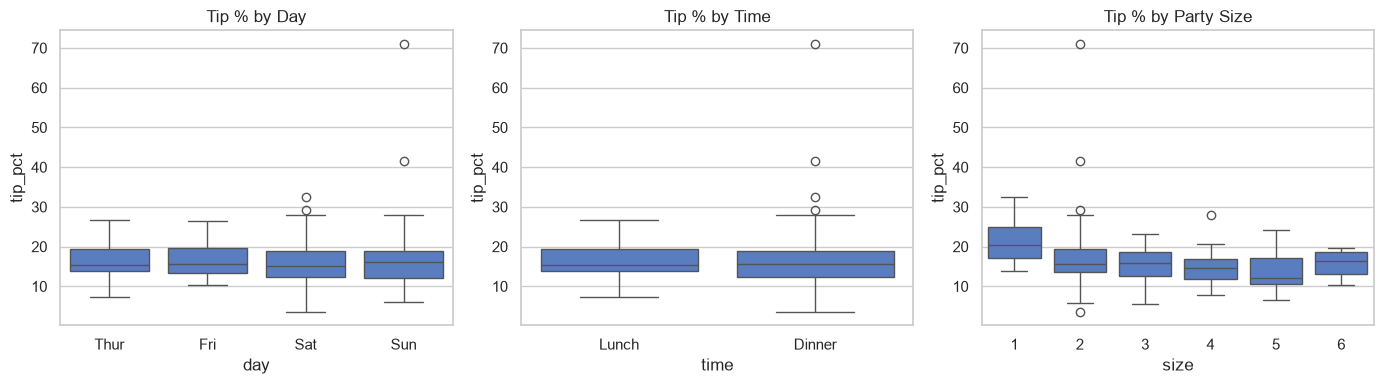

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=tips, x='day', y='tip_pct', ax=axes[0])
axes[0].set_title('Tip % by Day')
sns.boxplot(data=tips, x='time', y='tip_pct', ax=axes[1])
axes[1].set_title('Tip % by Time')
sns.boxplot(data=tips, x='size', y='tip_pct', ax=axes[2])
axes[2].set_title('Tip % by Party Size')
plt.tight_layout()
plt.show()


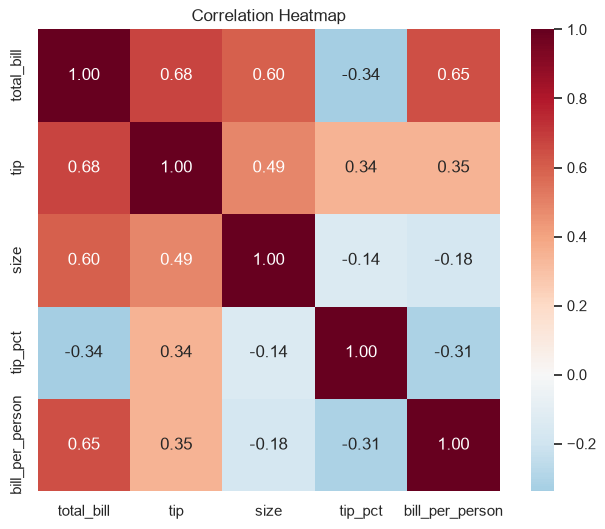

In [9]:
corr = tips[['total_bill', 'tip', 'size', 'tip_pct', 'bill_per_person']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='RdBu_r', center=0, fmt='.2f', square=True)
plt.title('Correlation Heatmap')
plt.show()


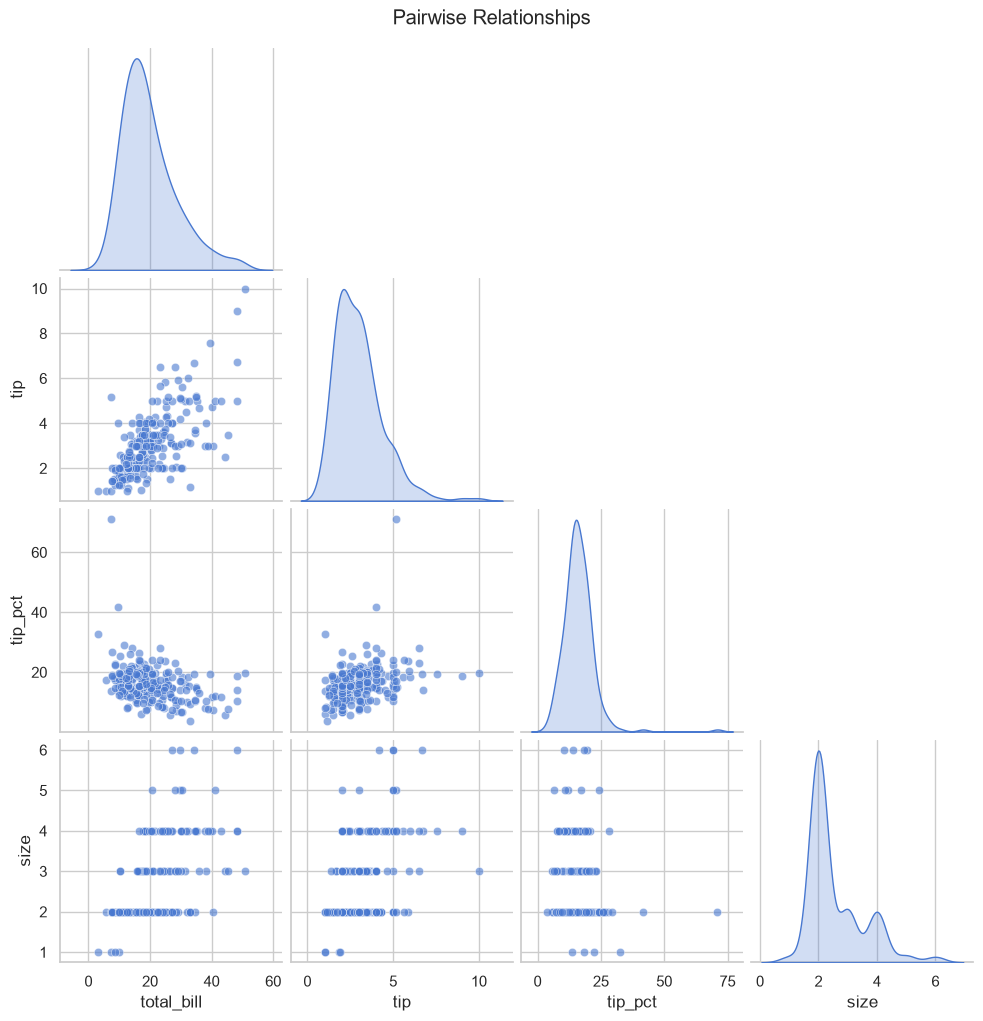

In [10]:
sns.pairplot(tips[['total_bill', 'tip', 'tip_pct', 'size']], 
             diag_kind='kde', corner=True, plot_kws={'alpha': 0.6})
plt.suptitle('Pairwise Relationships', y=1.02)
plt.show()


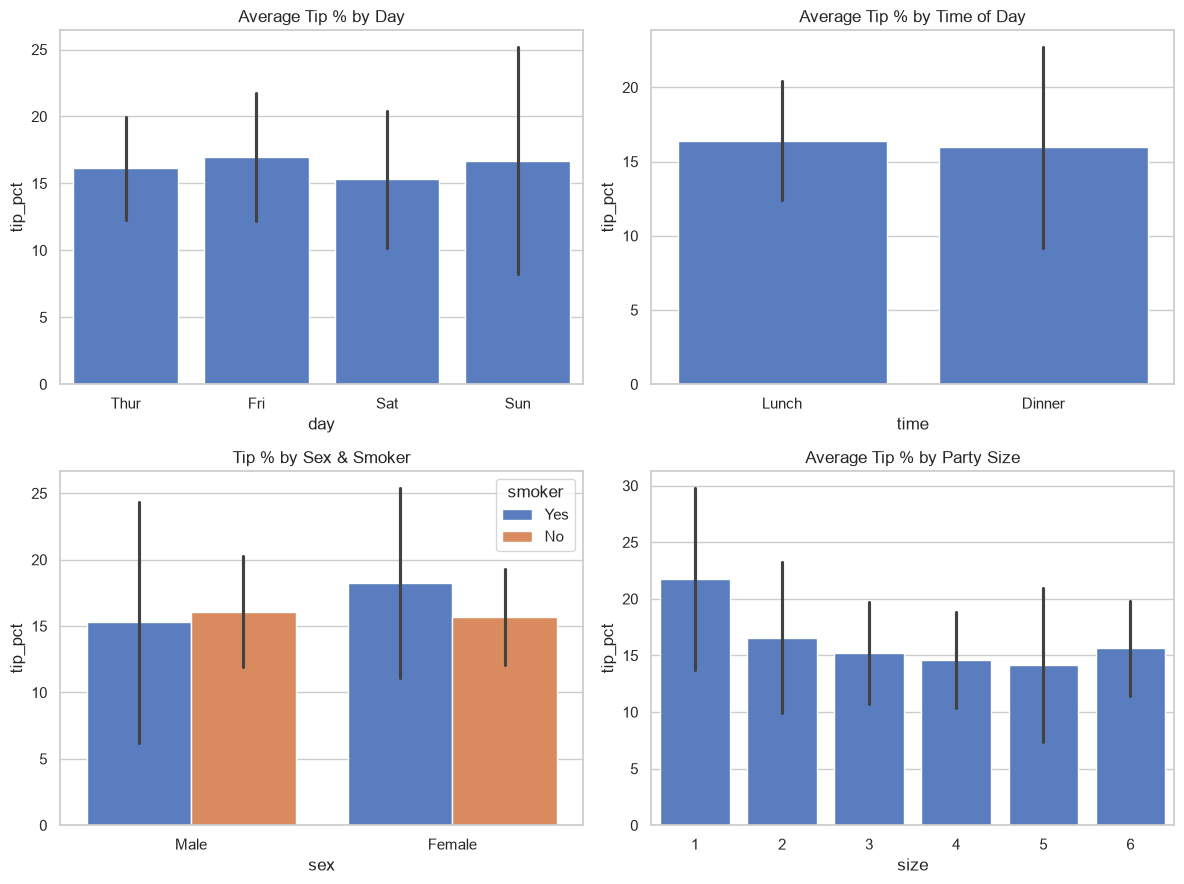

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.barplot(data=tips, x='day', y='tip_pct', ax=axes[0,0], errorbar='sd')
axes[0,0].set_title('Average Tip % by Day')

sns.barplot(data=tips, x='time', y='tip_pct', ax=axes[0,1], errorbar='sd')
axes[0,1].set_title('Average Tip % by Time of Day')

sns.barplot(data=tips, x='sex', y='tip_pct', hue='smoker', ax=axes[1,0], errorbar='sd')
axes[1,0].set_title('Tip % by Sex & Smoker')

sns.barplot(data=tips, x='size', y='tip_pct', ax=axes[1,1], errorbar='sd')
axes[1,1].set_title('Average Tip % by Party Size')

plt.tight_layout()
plt.show()


In [12]:
print("Correlation of features with high_tipper:")
print(tips[['total_bill', 'tip', 'tip_pct', 'size', 'bill_per_person']].corrwith(tips['high_tipper']).sort_values(ascending=False))

print("\n--- Smell test results ---")
print("1. 'tip' itself: DIRECT LEAKAGE (the tip amount is what we are trying to understand/predict)")
print("2. 'tip_pct': DIRECT LEAKAGE (high_tipper is defined from tip_pct)")
print("3. 'total_bill': Not leakage, but strongly related (larger bills tend to have higher absolute tips)")
print("4. 'size': Safe – known before the tip is given")
print("5. 'sex', 'smoker', 'day', 'time': Safe – known before or at the time of service")


Correlation of features with high_tipper:
tip_pct            0.65
tip                0.34
bill_per_person   -0.10
size              -0.12
total_bill        -0.16
dtype: float64

--- Smell test results ---
1. 'tip' itself: DIRECT LEAKAGE (the tip amount is what we are trying to understand/predict)
2. 'tip_pct': DIRECT LEAKAGE (high_tipper is defined from tip_pct)
3. 'total_bill': Not leakage, but strongly related (larger bills tend to have higher absolute tips)
4. 'size': Safe – known before the tip is given
5. 'sex', 'smoker', 'day', 'time': Safe – known before or at the time of service


In [13]:
print("""
Practical guidance for modeling:
- If predicting tip AMOUNT → do NOT use tip_pct or high_tipper as features.
- If predicting tip PERCENTAGE → do NOT use tip or high_tipper as features.
- Safe features available at service time: total_bill (or estimated), size, day, time, sex, smoker.
""")



Practical guidance for modeling:
- If predicting tip AMOUNT → do NOT use tip_pct or high_tipper as features.
- If predicting tip PERCENTAGE → do NOT use tip or high_tipper as features.
- Safe features available at service time: total_bill (or estimated), size, day, time, sex, smoker.



             mean  count  std
day  time                    
Fri  Lunch  18.88      7 4.59
Sun  Dinner 16.69     76 8.47
Thur Lunch  16.13     61 3.90
     Dinner 15.97      1  NaN
Fri  Dinner 15.89     12 4.70
Sat  Dinner 15.32     87 5.13


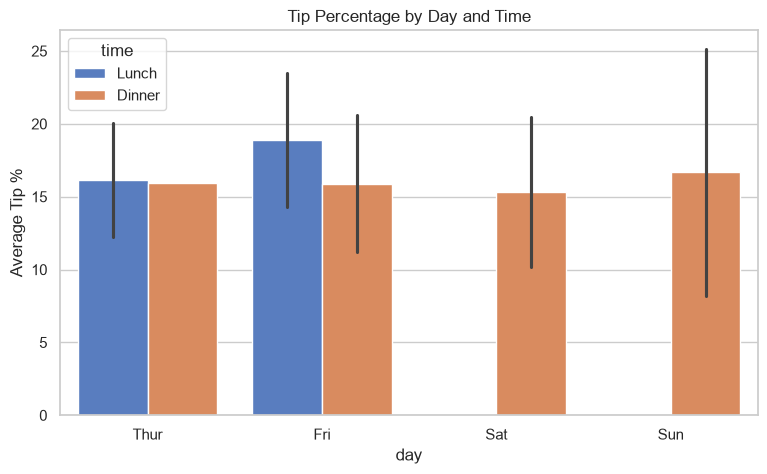

In [14]:
day_time = tips.groupby(['day', 'time'])['tip_pct'].agg(['mean', 'count', 'std']).round(2)
print(day_time.sort_values('mean', ascending=False))

plt.figure(figsize=(9, 5))
sns.barplot(data=tips, x='day', y='tip_pct', hue='time', errorbar='sd')
plt.title('Tip Percentage by Day and Time')
plt.ylabel('Average Tip %')
plt.show()

      mean  median  count
size                     
1    21.73   20.28      4
2    16.57   15.61    156
3    15.22   15.93     38
4    14.59   14.67     37
5    14.15   12.14      5
6    15.62   16.29      4


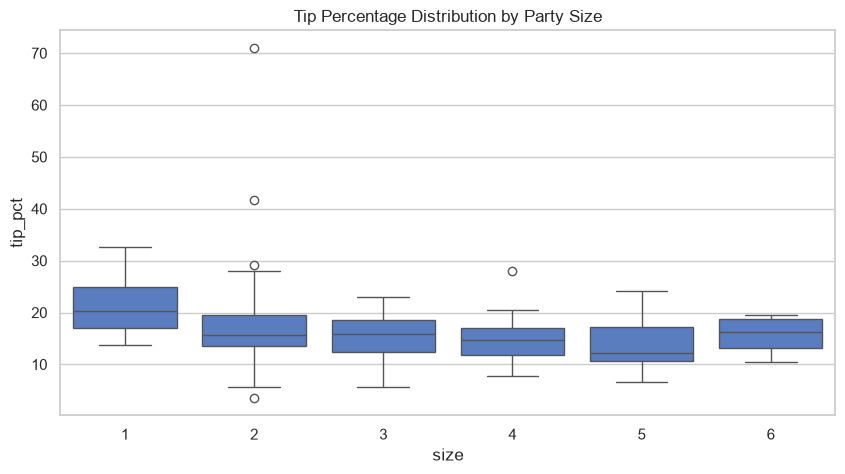

In [15]:
size_stats = tips.groupby('size')['tip_pct'].agg(['mean', 'median', 'count']).round(2)
print(size_stats)

sns.boxplot(data=tips, x='size', y='tip_pct')
plt.title('Tip Percentage Distribution by Party Size')
plt.show()

Tip % by smoker:
        mean  median  count
smoker                     
Yes    16.32   15.38     93
No     15.93   15.56    151

Tip % by sex:
        mean  median  count
sex                        
Male   15.77   15.35    157
Female 16.65   15.56     87

Cross tab (sex × smoker):
smoker   Yes    No
sex               
Male   15.28 16.07
Female 18.22 15.69


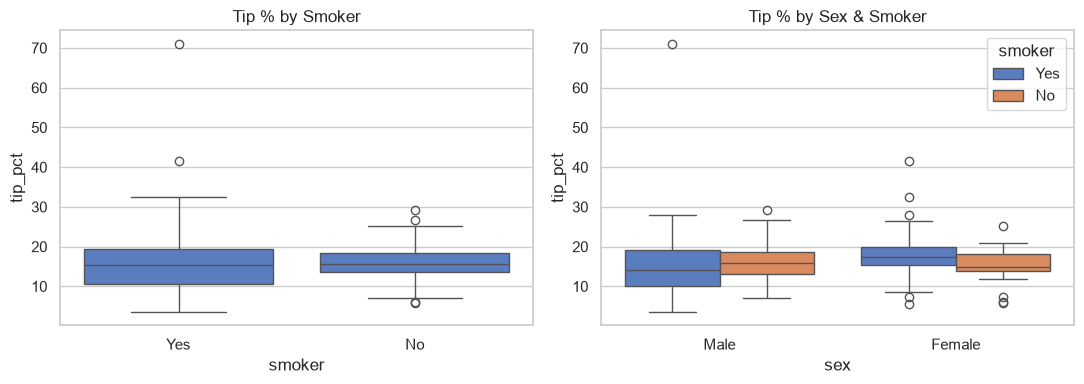

In [16]:
print("Tip % by smoker:")
print(tips.groupby('smoker')['tip_pct'].agg(['mean', 'median', 'count']).round(2))

print("\nTip % by sex:")
print(tips.groupby('sex')['tip_pct'].agg(['mean', 'median', 'count']).round(2))

print("\nCross tab (sex × smoker):")
print(tips.groupby(['sex', 'smoker'])['tip_pct'].mean().unstack().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=tips, x='smoker', y='tip_pct', ax=axes[0])
axes[0].set_title('Tip % by Smoker')
sns.boxplot(data=tips, x='sex', y='tip_pct', hue='smoker', ax=axes[1])
axes[1].set_title('Tip % by Sex & Smoker')
plt.tight_layout()
plt.show()